# **ROTATING EQUIPMENT ANOMALY DETECTION**
During the Anomaly Detection phase, the algorithm identifies samples in data set which differ from the normal
operation condition.
We worked on data collected by ENI on rotating machines.


## Setup

In [2]:
!pip install scikit-optimize
!pip install tqdm

In [3]:
from google.colab import drive
drive.mount('/content/drive/', force_remount=True)

Mounted at /content/drive/


In [4]:
import sys
sys.path.append('/content/drive/MyDrive/AI_Industry_Data/AI_Industry_Davide_Luca_Guglielmo_14_10_2024')
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from utils import *
from models.AE import AE
from models.AE_LSTM import AE_LSTM
from models.VAE import VAE
from models.VAE_LSTM import VAE_LSTM
from sklearn.preprocessing import StandardScaler
from datetime import datetime
import torch.nn.functional as F
import torch
from tqdm import tqdm
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import mean_squared_error

from sklearn.metrics import f1_score
from sklearn.model_selection import KFold
from skopt import gp_minimize
from skopt.space import Real
# Create my DatasetClass
from torch.utils.data import DataLoader,Dataset
from torch import nn

In [5]:
figsize=(18, 6)

# Machine: V360KB11E

## Dataset download


In [6]:
name_machine = 'V360KB011E'
# old data
dataset_folder_old = f"/content/drive/MyDrive/AI_Industry_Data/old_data/train_V360KB011E_idtraining_849/"
# new data
dataset_folder_new = f"/content/drive/MyDrive/AI_Industry_Data/new_data/V360KB11E/"

# old data
noc_data_old = pd.read_csv(dataset_folder_old + f"noc_data_{name_machine}_849.csv",sep=",")
sensor_data_old = pd.read_csv(dataset_folder_old + f"sensor_data_{name_machine}_849.csv",sep=",")
#sensor_data_old.drop(['COVA.ABB.V470-A018-A.pv', 'COVA.ABB.V470-A028-A.pv'], axis=1, inplace=True) # removing two sensors beacuse thery're missing in new data
train_card_old = pd.read_csv(dataset_folder_old + f"train_card_{name_machine}_849.csv",sep=",")


# new data
confirmed_anomalies_new = pd.read_excel(dataset_folder_new + f"11E_confirmed_anomalies.xlsx")
sensor_data_new = pd.read_csv(dataset_folder_new + f"11E_sensorsdata_new.csv", sep=",")
confirmed_anomalies_new.rename(columns={'anomaly_start': 'range_start', 'anomaly_end': 'range_end'}, inplace=True)
confirmed_anomalies_new["range_start"] = confirmed_anomalies_new.apply(lambda x : str(x["range_start"]),axis=1)
confirmed_anomalies_new["range_end"] = confirmed_anomalies_new.apply(lambda x : str(x["range_end"]),axis=1)




In [7]:
# Cols to consider
target_cols = list(set(sensor_data_old.columns) & set(sensor_data_new.columns)) # since the old and the new data have some columns that dont match, we consider only the common columns
sensor_data_old = sensor_data_old[target_cols]
sensor_data_new = sensor_data_new[target_cols]
target_cols.remove('sensor_ts')

In [8]:
print(target_cols)

['COVA.ABB.V360-TE732E.pv', 'COVA.ABB.V360-ZT437P.pv', 'COVA.ABB.V360-TE766E.pv', 'COVA.ABB.V360TT431.pv', 'COVA.ABB.V360KB011ET.pv', 'COVA.ABB.V470-A155-A.pv', 'COVA.ABB.V360II042.pv', 'COVA.ABB.V360-TE762E.pv', 'COVA.ABB.V360-PT704E.pv', 'COVA.ABB.V360-TT702E.pv', 'COVA.ABB.V360-PT701E.pv', 'COVA.ABB.V360-PT731E.pv', 'COVA.ABB.V360PIC437.pv', 'COVA.ABB.V360TT432.pv', 'COVA.ABB.V360-TE764E.pv', 'COVA.ABB.V360LIC433.pv', 'COVA.ABB.V360TIC433.pv', 'COVA.ABB.V360PIC437.out', 'COVA.ABB.V360-TE731E.pv', 'COVA.ABB.V360FT431.pv', 'COVA.ABB.V360PIC433.pv', 'COVA.ABB.V360TIC433.pvl', 'COVA.ABB.V360FY431.pv', 'COVA.ABB.V360-TT704E.pv', 'COVA.ABB.V360PT432.pv', 'COVA.ABB.V360PV437.pv', 'COVA.ABB.V360-TT706E.pv', 'COVA.ABB.V360PIC433.mv', 'Eni.VDA.KPI.V360-KB-011E.CompEfficiency', 'COVA.ABB.V360-TT703E.pv', 'COVA.ABB.V360-TT734E.pv']


`noc_data` contains the time intervals in which we assumes there are not anomalies (NOC == _Normal Operating Conditions_).

In [9]:
noc_data_old.head()

,id_training,range_start,range_end,id_train
0,849,2022-11-26 00:00:00,2022-12-11 13:20:00,V360KB011E
1,849,2022-12-12 18:24:30,2022-12-22 23:50:00,V360KB011E
2,849,2023-01-29 04:14:30,2023-02-24 00:20:00,V360KB011E
3,849,2023-02-24 17:04:30,2023-07-19 00:00:00,V360KB011E


`confirmed_anomalies` contains the time intervals in which we know there are anomalies.

In [10]:
confirmed_anomalies_new.head()

,range_start,range_end
0,2024-11-05 00:00:00,2024-11-06 00:00:00
1,2024-11-15 00:00:00,2024-11-20 00:00:00


Each row in `train_card` contains the information about each sensor found in `sensor_data`.

In [11]:
train_card_old.head()

,id_train,asset_id,train_type,equipment_type,id_sensor,unit,is_operating,will_be_available,pi_acquisition_date,pi_description,sensor_description,tag_id,priority,for_ml,onoff_parameter,boot_threshold,efficiency_index
0,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-PT701E.pv,bar,1.0,2.0,NaN,P asp,Suction Pressure,1.0,1.0,1,0,0,0
1,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-PT704E.pv,bar,1.0,2.0,NaN,P mand,Discharge Pressure,2.0,1.0,1,0,0,0
2,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-PT731E.pv,bar,1.0,2.0,NaN,PRESS. OLIO LUBRIF.,Lube Oil Pressure,3.0,1.0,1,0,0,0
3,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-TT702E.pv,degC,1.0,2.0,NaN,TEMP.PREMIST.CIL.2,Packing Temperature - Cylinder2,4.0,1.0,1,0,0,0
4,V360KB011E,COVA,HP Compressor,Compressor,COVA.ABB.V360-TT703E.pv,degC,1.0,2.0,NaN,TEMP.PREMIST.CIL.1,Packing Temperature - Cylinder 1,5.0,1.0,1,0,0,0


`sensor_data` contains the real data (time series), i.e. the values for each sesnor every 30 seconds.

In [12]:
print(sensor_data_old.shape)
sensor_data_old.head(-1)

(675660, 32)


,COVA.ABB.V360-TE732E.pv,COVA.ABB.V360-ZT437P.pv,COVA.ABB.V360-TE766E.pv,COVA.ABB.V360TT431.pv,COVA.ABB.V360KB011ET.pv,COVA.ABB.V470-A155-A.pv,COVA.ABB.V360II042.pv,COVA.ABB.V360-TE762E.pv,COVA.ABB.V360-PT704E.pv,COVA.ABB.V360-TT702E.pv,...,COVA.ABB.V360FY431.pv,COVA.ABB.V360-TT704E.pv,sensor_ts,COVA.ABB.V360PT432.pv,COVA.ABB.V360PV437.pv,COVA.ABB.V360-TT706E.pv,COVA.ABB.V360PIC433.mv,Eni.VDA.KPI.V360-KB-011E.CompEfficiency,COVA.ABB.V360-TT703E.pv,COVA.ABB.V360-TT734E.pv
0,47.107459,44.281385,28.989776,30.474876,97721.459174,6.846464,110.183693,30.505851,56.456651,54.776807,...,18446.190909,101.363724,2022-11-26 01:00:00,57.15625,32.367333,107.852379,56.46875,0.568641,52.038667,34.749411
1,47.220074,44.315727,29.098574,30.489597,97721.467521,6.843984,110.170470,30.616768,56.453694,54.863184,...,18440.617107,101.408075,2022-11-26 01:00:30,57.15625,32.430591,107.915221,56.46875,0.570677,52.157014,34.888424
2,47.331862,44.367178,29.206409,30.504318,97721.475868,6.841505,110.157247,30.726641,56.449993,54.948369,...,18435.093967,101.451332,2022-11-26 01:01:00,57.15625,32.529807,107.976851,56.46875,0.572638,52.274146,35.025274
3,47.442824,44.448753,29.313280,30.519039,97721.484132,6.839026,110.144024,30.835472,56.445546,55.032362,...,18429.621405,101.493496,2022-11-26 01:01:30,57.15625,32.654611,108.037269,56.46875,0.574527,52.390064,35.159961
4,47.552184,44.558997,29.419187,30.533760,97721.492479,6.836546,110.130801,30.943260,56.440353,55.115164,...,18425.329091,101.534568,2022-11-26 01:02:00,57.15625,32.804807,108.096321,56.46875,0.576342,52.504767,35.292485
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
675654,32.556127,1.289472,29.898394,35.072882,102027.100000,22.366689,0.200001,31.369567,23.177872,39.437803,...,-11.140057,33.888245,2023-07-18 23:57:00,23.03125,28.083959,31.427677,23.84375,0.000000,39.624890,26.080434
675655,32.553261,1.290112,29.897953,35.062965,102027.100000,22.362657,0.200001,31.367781,23.177650,39.430235,...,-11.140210,33.879013,2023-07-18 23:57:30,23.03125,27.956489,31.420693,23.84375,0.000000,39.617938,26.071488
675656,32.550389,1.290753,29.897493,35.053047,102027.100000,22.358212,0.200001,31.365993,23.177370,39.422666,...,-11.140362,33.871340,2023-07-18 23:58:00,23.03125,27.829519,31.413975,23.84375,0.000000,39.610988,26.062551
675657,32.547512,1.291395,29.897012,35.043130,102027.100000,22.353982,0.200001,31.364205,23.177033,39.415096,...,-11.140515,33.865228,2023-07-18 23:58:30,23.03125,27.703047,31.407522,23.84375,0.000000,39.604041,26.053624


In [13]:
sensor_data_new["sensor_ts"] = sensor_data_new.apply(lambda x : x["sensor_ts"].replace("T", " ")[:-6],axis=1)

In [14]:
print(sensor_data_new.shape)
sensor_data_new.head()

(1405321, 32)


,COVA.ABB.V360-TE732E.pv,COVA.ABB.V360-ZT437P.pv,COVA.ABB.V360-TE766E.pv,COVA.ABB.V360TT431.pv,COVA.ABB.V360KB011ET.pv,COVA.ABB.V470-A155-A.pv,COVA.ABB.V360II042.pv,COVA.ABB.V360-TE762E.pv,COVA.ABB.V360-PT704E.pv,COVA.ABB.V360-TT702E.pv,...,COVA.ABB.V360FY431.pv,COVA.ABB.V360-TT704E.pv,sensor_ts,COVA.ABB.V360PT432.pv,COVA.ABB.V360PV437.pv,COVA.ABB.V360-TT706E.pv,COVA.ABB.V360PIC433.mv,Eni.VDA.KPI.V360-KB-011E.CompEfficiency,COVA.ABB.V360-TT703E.pv,COVA.ABB.V360-TT734E.pv
0,32.75,1.31,30.21061,37.35,102027.1,22.31196,0.200001,31.5,23.06,40.01889,...,-11.10116,34.67683,2023-07-23 00:00:00,23.03125,33.44617,32.89510,23.84375,0.0,40.50402,28.23155
1,32.75,1.31,30.21861,37.35,102027.1,22.30000,0.200001,31.5,23.06,40.01421,...,-11.10133,34.81180,2023-07-23 00:00:30,23.03125,32.89762,33.02011,23.84375,0.0,40.50022,28.22141
2,32.75,1.31,30.22661,37.35,102027.1,22.30000,0.200001,31.5,23.06,40.00952,...,-11.10150,34.94677,2023-07-23 00:01:00,23.03125,32.34906,33.14513,23.84375,0.0,40.49641,28.21128
3,32.75,1.31,30.23461,37.35,102027.1,22.30000,0.200001,31.5,23.06,40.00483,...,-11.10168,35.06709,2023-07-23 00:01:30,23.03125,31.80050,33.25138,23.84375,0.0,40.49261,28.20114
4,32.75,1.31,30.24261,37.35,102027.1,22.30000,0.200001,31.5,23.06,40.00015,...,-11.10185,35.11108,2023-07-23 00:02:00,23.03125,31.25195,33.25995,23.84375,0.0,40.48881,28.19101


### Adding `NOC` and `anomalies` columns


In [15]:
# adding NOC label based on NOC intervals - train
#sensor_data_training = consider_range(noc_data_old, sensor_data_old)
#sensor_data_training = add_labels(sensor_data_old, sensor_data_training, labels = 'NOC')

In [16]:
# adding anomaly label based on anomaly intervals - test
sensor_data_testing = consider_range(confirmed_anomalies_new, sensor_data_new)
sensor_data_testing = add_labels(sensor_data_new, sensor_data_testing, labels = 'anomaly')

In [17]:
# eliminate useless colums from train card
train_card_old = cut_col(train_card_old)

In [18]:
sensor_data_new[sensor_data_new['anomaly']==1].head(-1)

,COVA.ABB.V360-TE732E.pv,COVA.ABB.V360-ZT437P.pv,COVA.ABB.V360-TE766E.pv,COVA.ABB.V360TT431.pv,COVA.ABB.V360KB011ET.pv,COVA.ABB.V470-A155-A.pv,COVA.ABB.V360II042.pv,COVA.ABB.V360-TE762E.pv,COVA.ABB.V360-PT704E.pv,COVA.ABB.V360-TT702E.pv,...,COVA.ABB.V360-TT704E.pv,sensor_ts,COVA.ABB.V360PT432.pv,COVA.ABB.V360PV437.pv,COVA.ABB.V360-TT706E.pv,COVA.ABB.V360PIC433.mv,Eni.VDA.KPI.V360-KB-011E.CompEfficiency,COVA.ABB.V360-TT703E.pv,COVA.ABB.V360-TT734E.pv,anomaly
1356360,56.63118,36.56873,69.21095,30.7125,102507.7,7.688012,143.7690,71.49667,63.96000,68.44618,...,110.9883,2024-11-05 00:00:00,64.34375,29.73436,111.3100,63.1875,0.697484,62.96420,46.43114,1
1356361,56.62895,37.15544,69.19557,30.7125,102507.8,7.661961,144.5447,71.48579,63.96000,68.43812,...,110.9467,2024-11-05 00:00:30,64.34375,30.12265,111.3018,63.1875,0.697387,62.96040,46.41834,1
1356362,56.62672,37.58839,69.18019,30.7125,102507.8,7.611910,143.8578,71.47492,63.96000,68.43005,...,110.9050,2024-11-05 00:01:00,64.34375,30.51095,111.2501,63.1875,0.697289,62.95660,46.40555,1
1356363,56.62449,37.46710,69.16482,30.7125,102507.8,7.638061,143.0587,71.46406,63.96000,68.42199,...,110.8600,2024-11-05 00:01:30,64.34375,30.89925,111.1984,63.1875,0.697192,62.95281,46.39275,1
1356364,56.62226,35.27291,69.14944,30.7125,102507.8,7.688006,143.7884,71.45319,63.96000,68.41393,...,110.7975,2024-11-05 00:02:00,64.34375,31.28754,111.1468,63.1875,0.697094,62.94901,46.37996,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1399555,57.27906,36.83146,72.82935,32.2875,102867.7,13.600000,142.3028,74.87000,64.08685,69.42475,...,112.6167,2024-11-19 23:57:30,64.37500,29.79741,112.9127,63.3125,0.703908,64.81000,47.59387,1
1399556,57.27900,37.52643,72.82326,32.2875,102867.7,13.600000,143.0893,74.87000,64.05518,69.42020,...,112.5962,2024-11-19 23:58:00,64.37500,30.33688,112.9602,63.3125,0.703844,64.81000,47.59337,1
1399557,57.27893,38.22140,72.81715,32.2875,102867.7,13.600000,143.9386,74.87000,64.02349,69.41563,...,112.5756,2024-11-19 23:58:30,64.37500,30.87040,112.9966,63.3125,0.703780,64.81000,47.59287,1
1399558,57.27887,38.91637,72.81106,32.2875,102867.7,13.600000,143.1877,74.87000,63.99181,69.41107,...,112.5550,2024-11-19 23:59:00,64.37500,31.40392,112.9758,63.3125,0.703716,64.81000,47.59237,1


## Pre-Processing
We have replicated the ENI preprocessing which involves the following steps:

1.   Drop offline time ranges-on/off parameter given
2.   Drop nan
3.   Scale the data
4.   Exclude flat sensors
5.   Smooth with rolling average

### 1.   Drop offline time ranges-on/off parameter given

In [19]:
# Drop offline time ranges – On/Off parameter given
print("old Dataset shape before dropping: ", len(sensor_data_old))

data_to_remove = train_card_old[train_card_old['onoff_parameter']== 1 ][['boot_threshold','id_sensor']].groupby('id_sensor').first().reset_index()
for i in range(len(data_to_remove)):
  dtr = data_to_remove.iloc[i]
  sensor_data_old = sensor_data_old.drop(np.where(sensor_data_old[dtr['id_sensor']] <= dtr['boot_threshold'])[0])

print("old Dataset shape after dropping: ", len(sensor_data_old))

print("new Dataset shape before dropping: ", len(sensor_data_new))

for i in range(len(data_to_remove)):
  dtr = data_to_remove.iloc[i]
  sensor_data_new = sensor_data_new.drop(np.where(sensor_data_new[dtr['id_sensor']] <= dtr['boot_threshold'])[0])

print("new Dataset shape after dropping: ", len(sensor_data_new))


old Dataset shape before dropping:  675660
old Dataset shape after dropping:  516737
new Dataset shape before dropping:  1405321
new Dataset shape after dropping:  106869


### 2.   Drop NaN


In [20]:
print("Old dataset shape before dropping:", sensor_data_old.shape)
print("New dataset shape before dropping:", sensor_data_new.shape)
print()

# Drop columns and rows where all values are NaN - train
sensor_data_old.dropna(axis=0, how='all', subset=target_cols, inplace=True)
sensor_data_old.dropna(axis=1, how='all', inplace=True)

# Drop columns and rows where all values are NaN - test
sensor_data_new.dropna(axis=0, how='all', subset=target_cols, inplace=True)
sensor_data_new.dropna(axis=1, how='all', inplace=True)

# Drop rows with NaN values
sensor_data_old = sensor_data_old.dropna()
sensor_data_new = sensor_data_new.dropna()

# Reset the index
sensor_data_old.reset_index(drop=True, inplace=True)
sensor_data_new.reset_index(drop=True, inplace=True)

print("Old dataset shape after dropping:", sensor_data_old.shape)
print("New dataset shape after dropping:", sensor_data_new.shape)

Old dataset shape before dropping: (516737, 32)
New dataset shape before dropping: (106869, 33)

Old dataset shape after dropping: (516737, 32)
New dataset shape after dropping: (106505, 33)


### 3.   Scale the data


In [21]:
##Scaler fitted on the training and testing data and applied to all the dataset (the training must be independent from the test)

# Initialize the StandardScaler
scaler = StandardScaler()

# Train Test = NOC data
# training_data = sensor_data_old[sensor_data['NOC'] == 1]

train_data = sensor_data_old.drop('sensor_ts', axis=1)
test_data = sensor_data_new.drop(['sensor_ts', 'anomaly'], axis=1)

train_ts = sensor_data_old['sensor_ts']
test_ts = sensor_data_new['sensor_ts']
anomaly_column = sensor_data_new['anomaly']

# Fit the Scaler with train_data
scaler.fit(train_data)

# Transform data usign the Scaler
scaled_train_data = scaler.transform(train_data)
scaled_test_data = scaler.transform(test_data)

# Convert the scaled data back to a DataFrame
scaled_train_df = pd.DataFrame(scaled_train_data, index=train_data.index, columns=train_data.columns)
scaled_train_df.insert(0, 'sensor_ts', train_ts)

scaled_test_df = pd.DataFrame(scaled_test_data, index=test_data.index, columns=test_data.columns)
scaled_test_df.insert(0, 'sensor_ts', test_ts)
scaled_test_df['anomaly'] = anomaly_column.values

# index reset
scaled_train_df = scaled_train_df.reset_index(drop = True)
scaled_test_df = scaled_test_df.reset_index(drop = True)

In [22]:
scaled_train_df.head()

,sensor_ts,COVA.ABB.V360-TE732E.pv,COVA.ABB.V360-ZT437P.pv,COVA.ABB.V360-TE766E.pv,COVA.ABB.V360TT431.pv,COVA.ABB.V360KB011ET.pv,COVA.ABB.V470-A155-A.pv,COVA.ABB.V360II042.pv,COVA.ABB.V360-TE762E.pv,COVA.ABB.V360-PT704E.pv,...,COVA.ABB.V360TIC433.pvl,COVA.ABB.V360FY431.pv,COVA.ABB.V360-TT704E.pv,COVA.ABB.V360PT432.pv,COVA.ABB.V360PV437.pv,COVA.ABB.V360-TT706E.pv,COVA.ABB.V360PIC433.mv,Eni.VDA.KPI.V360-KB-011E.CompEfficiency,COVA.ABB.V360-TT703E.pv,COVA.ABB.V360-TT734E.pv
0,2022-11-26 01:00:00,-12.781766,0.965044,-4.167907,0.649458,-1.732101,-0.383854,-2.007467,-4.174698,-0.848285,...,-0.094024,-1.916685,-0.532539,-0.768349,0.936063,0.410439,-0.725468,-3.212245,-2.987163,-11.482177
1,2022-11-26 01:00:30,-12.631249,0.968208,-4.153143,0.655013,-1.732094,-0.384318,-2.008909,-4.159808,-0.849182,...,-0.062517,-1.918961,-0.523853,-0.768349,0.942489,0.421296,-0.725468,-3.153135,-2.936297,-11.347550
2,2022-11-26 01:01:00,-12.481838,0.972949,-4.138511,0.660567,-1.732087,-0.384782,-2.010350,-4.145058,-0.850305,...,-0.030786,-1.921217,-0.515382,-0.768349,0.952568,0.431943,-0.725468,-3.096158,-2.885952,-11.215016
3,2022-11-26 01:01:30,-12.333531,0.980465,-4.124010,0.666121,-1.732081,-0.385247,-2.011792,-4.130448,-0.851653,...,-0.030687,-1.923452,-0.507124,-0.768349,0.965246,0.442381,-0.725468,-3.041314,-2.836129,-11.084578
4,2022-11-26 01:02:00,-12.187365,0.990622,-4.109639,0.671675,-1.732074,-0.385711,-2.013233,-4.115978,-0.853228,...,-0.030687,-1.925205,-0.499080,-0.768349,0.980504,0.452582,-0.725468,-2.988603,-2.786829,-10.956234


In [23]:
scaled_test_df.head()

,sensor_ts,COVA.ABB.V360-TE732E.pv,COVA.ABB.V360-ZT437P.pv,COVA.ABB.V360-TE766E.pv,COVA.ABB.V360TT431.pv,COVA.ABB.V360KB011ET.pv,COVA.ABB.V470-A155-A.pv,COVA.ABB.V360II042.pv,COVA.ABB.V360-TE762E.pv,COVA.ABB.V360-PT704E.pv,...,COVA.ABB.V360FY431.pv,COVA.ABB.V360-TT704E.pv,COVA.ABB.V360PT432.pv,COVA.ABB.V360PV437.pv,COVA.ABB.V360-TT706E.pv,COVA.ABB.V360PIC433.mv,Eni.VDA.KPI.V360-KB-011E.CompEfficiency,COVA.ABB.V360-TT703E.pv,COVA.ABB.V360-TT734E.pv,anomaly
0,2023-09-15 19:00:00,-39.716499,-2.996938,-4.845742,2.557787,1.731763,2.758746,-10.709552,-4.878085,-10.399087,...,-9.454974,-14.402003,-10.555158,-0.197726,-12.990647,-10.271867,-19.733442,-9.774115,-18.815463,0
1,2023-09-15 19:00:30,-37.997767,-2.648923,-4.735466,2.207988,1.731763,2.740010,-7.158282,-4.761393,-10.342940,...,-9.454974,-14.089935,-9.758472,-0.158200,-12.717986,-10.118782,-19.685407,-9.666586,-18.886508,0
2,2023-09-15 19:01:00,-36.706051,-1.309203,-4.612574,1.761149,1.731843,2.721264,-6.812295,-4.627050,-8.946291,...,-9.370535,-13.459984,-8.411658,-0.388080,-12.601131,-9.536352,-19.637373,-9.140322,-18.957545,0
3,2023-09-15 19:01:30,-35.417328,-0.353185,-4.568814,1.293777,1.731843,2.716780,-6.716982,-4.581542,-7.540282,...,-9.279491,-12.597828,-6.775028,-0.619841,-12.484276,-8.920348,-19.589339,-8.611136,-19.028590,0
4,2023-09-15 19:02:00,-34.365043,-0.482279,-4.541681,0.929452,1.731843,2.716780,-6.535811,-4.554698,-5.797660,...,-9.257214,-10.509005,-4.939517,-0.733494,-12.367421,-7.152016,-19.541305,-8.081949,-19.099627,0


### 4.   Exclude flat sensors


In [24]:
# Find columns with constant values
constant_cols = scaled_train_df.columns[scaled_train_df.nunique() == 1]

print("Sensors with constant values :", constant_cols.values)
target_cols = list(set(target_cols) - set(constant_cols.values))

# Drop the constant columns from the DataFrame - both train and test
scaled_train_df = scaled_train_df.drop(columns=constant_cols)
scaled_test_df = scaled_test_df.drop(columns=constant_cols)

print("Old dataset shape after drop : ", scaled_train_df.shape)
print("New dataset shape after drop : ", scaled_test_df.shape)

Sensors with constant values : []
Old dataset shape after drop :  (516737, 32)
New dataset shape after drop :  (106505, 33)


### 5.   Smooth with rolling average

In [25]:
import gc
gc.collect()

156

In [26]:
# Smoothing
sensor_ts = scaled_train_df['sensor_ts']

scaled_train_df['sensor_ts'] = pd.to_datetime(scaled_train_df['sensor_ts'])

# Set the 'timestamp' column as the index
scaled_train_df.set_index('sensor_ts', inplace=True)

# Calculate the rolling mean using a 5-minute window, handling time gaps
scaled_train_df[target_cols] = scaled_train_df[target_cols].rolling('5min').mean()

# reset the index
scaled_train_df.reset_index(inplace=True)

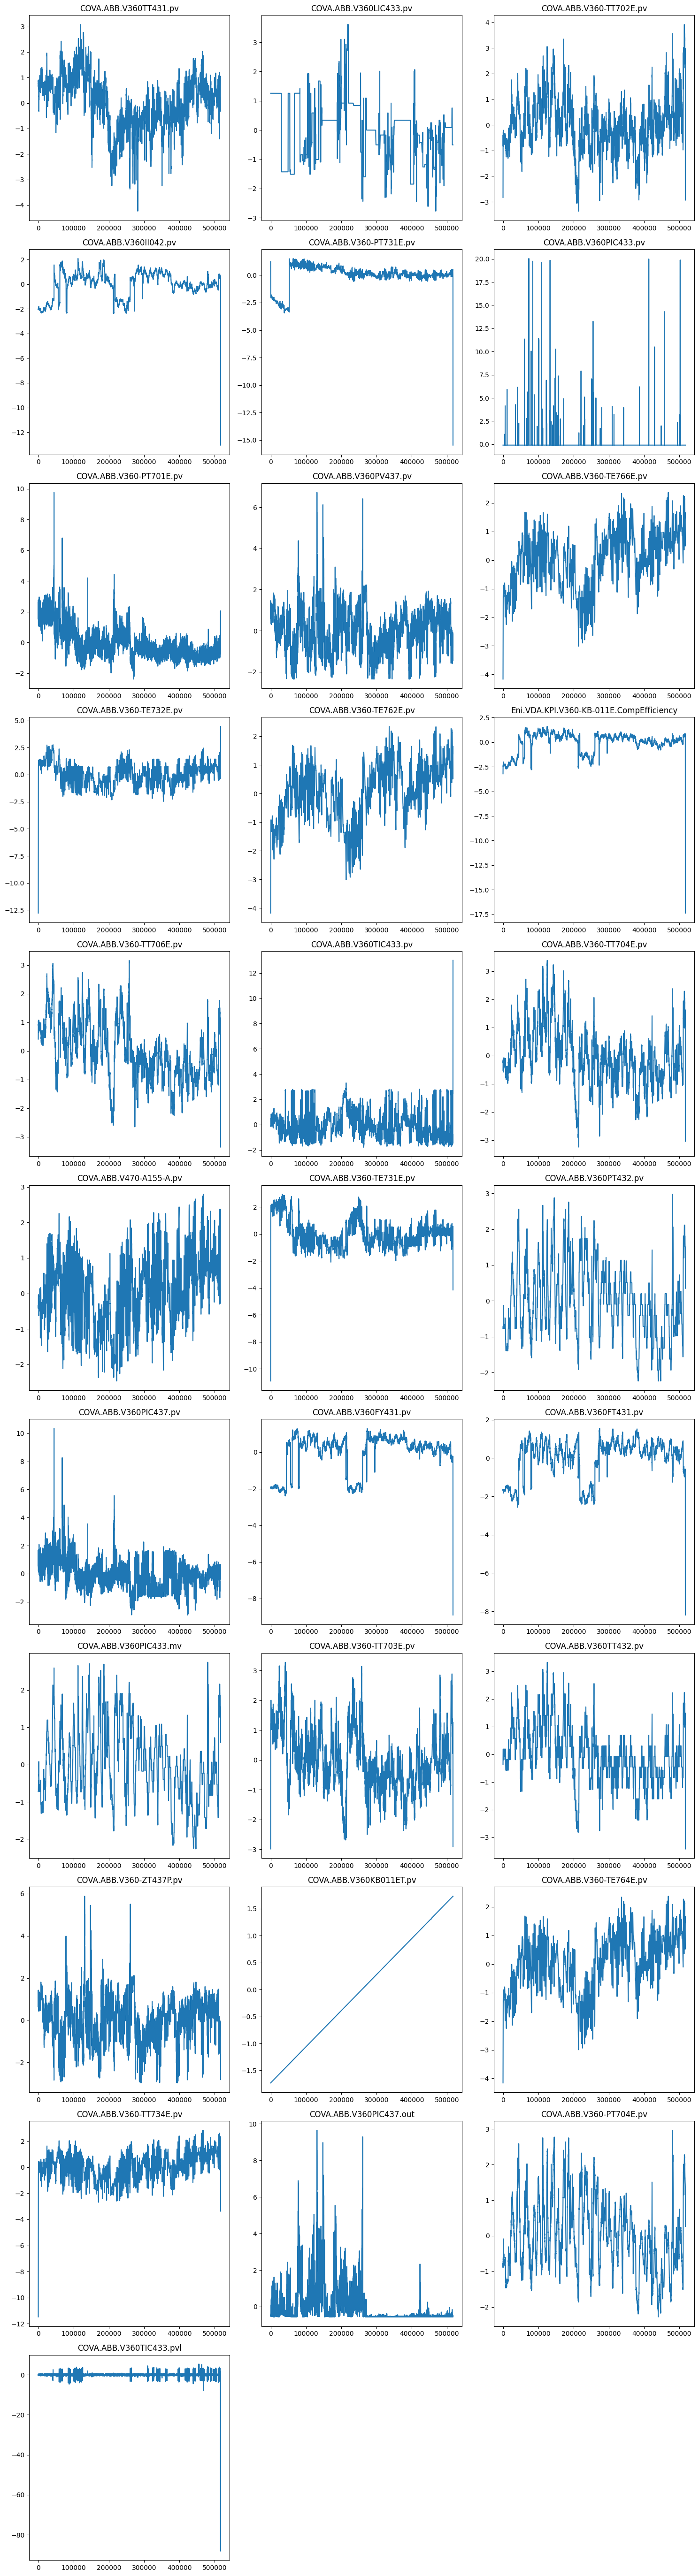

In [ ]:
plot_columns_in_grid(scaled_train_df, target_cols)

## Train/Test split


In [27]:
# Traing and Testing datasets
train_df = scaled_train_df
test_df = scaled_test_df

# Defining inputs of our model
inputs = target_cols

print("Train shape: ", train_df.shape)
print("Test shape: ", test_df.shape)

Train shape:  (516737, 32)
Test shape:  (106505, 33)


In [28]:
#tsdata = redistribute_nnoc(tsdata,n = 5)

# ***GMM*** - *Gaussian Mixture Model* (Baseline)

As a baseline we are using a **GMM**, namely a a probabilistic model that represents data as a mixture of multiple Gaussian distributions, each defined by its mean and covariance. It is often used for clustering, density estimation, or modeling complex distributions

In [29]:
import gc
gc.collect()

0

In [ ]:
# Define the parameter grid
param_grid = {'n_components': [2, 4, 8, 16]}

gmm = GaussianMixture(2)

opt = GridSearchCV(
    estimator=gmm,
    param_grid=param_grid,
    cv=3,
    verbose=3,    # Set to 3 for detailed logs
    n_jobs=-1     # Use all available CPU cores
)

gmm.fit(train_df[inputs])


# Print the best parameters
#print(f'Best parameters: {opt.best_params_}')

GaussianMixture(n_components=2)

In [ ]:
# This computes the log probability density of the data points in the test set
ldens = gmm.score_samples(test_df[inputs])
signal = pd.Series(index=test_df.index, data=-ldens)

##Find the best threshold

In [ ]:
gmm_best_threshold, gmm_best_score = threshold_optimization(signal, test_df['anomaly'], method = 'bayesian')

/usr/local/lib/python3.11/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [2.7998743683781346] before, using random point [184009.1466883487]
  warnings.warn(


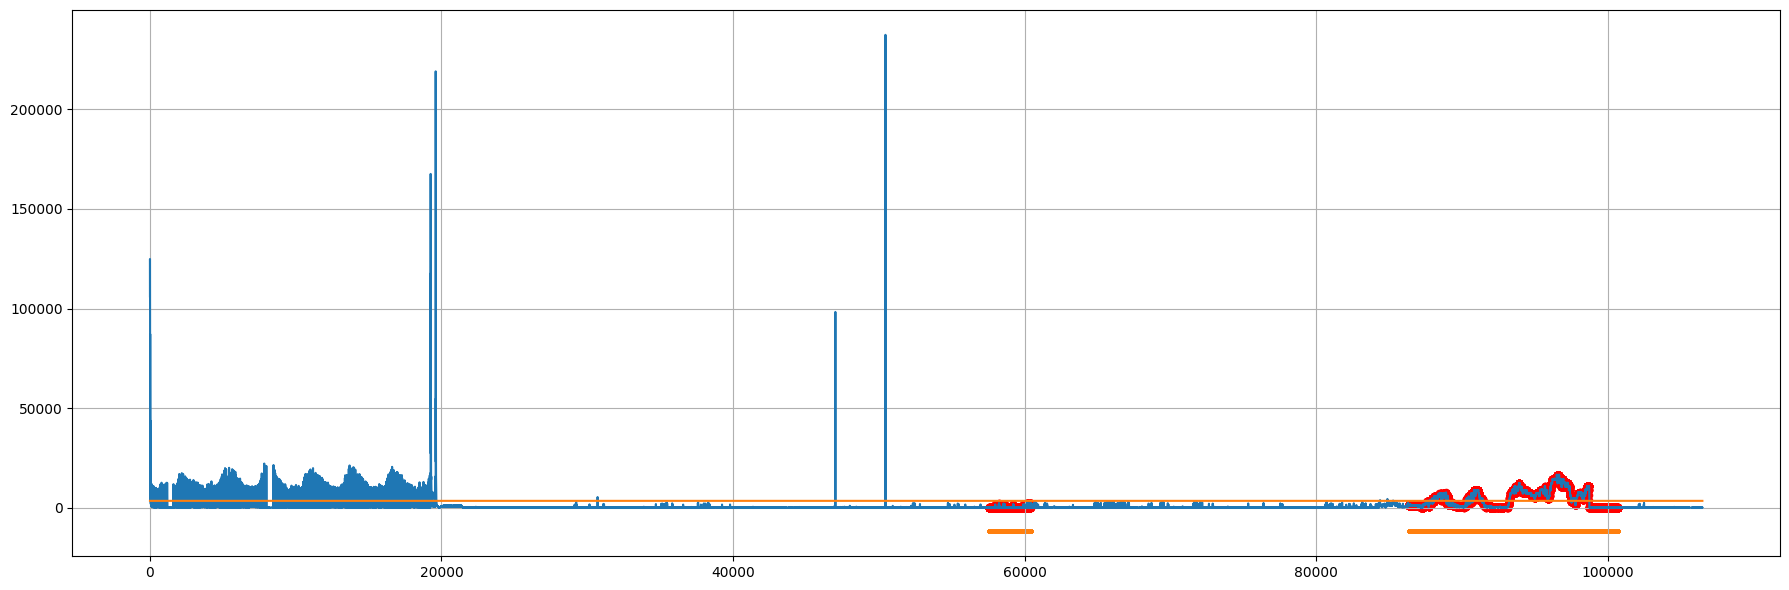

In [ ]:
plot_signal(signal, test_df['anomaly'], figsize=figsize, threshold = gmm_best_threshold)

#Deep Learning Models
After the GMM baseline we trained 4 different models (AE, AE_LSTM, VAE and VAE_LSTM)

In [30]:
gc.collect()

0

# Settings

In [31]:
batch_size = 32

if torch.cuda.is_available():
  device = torch.device("cuda:0")
else:
  device = torch.device("cpu")

# Define the dataset NOT SLIDED
train_df_dataset = MyDataset(train_df[target_cols], device =device)
test_df_dataset = MyDataset(test_df[target_cols], device =device)

# Define DataLoader
trdata_loader = DataLoader(train_df_dataset,batch_size=batch_size,shuffle=False)
tsdata_loader = DataLoader(test_df_dataset,batch_size=batch_size,shuffle=False)

In [32]:
input_size = len(target_cols)
hidden_size = 128
latent_size = 64
epochs = 10

# Train & Evaluation

In [33]:
true_labels = test_df['anomaly']

## AE

 A simple **Autoencoder** with two main components:

- Encoder: Two linear layers compress the input to a latent space.
- Decoder: Two linear layers reconstruct the input from the latent space.
The model uses **Mean Squared Error** (MSE) for reconstruction loss, and training is handled with the Adam optimizer. It includes early stopping for efficiency, and there are methods for evaluation, prediction, and plotting loss history to monitor performance.

Output: A reconstructed version of the input and a reconstruction error signal with the same size of input.

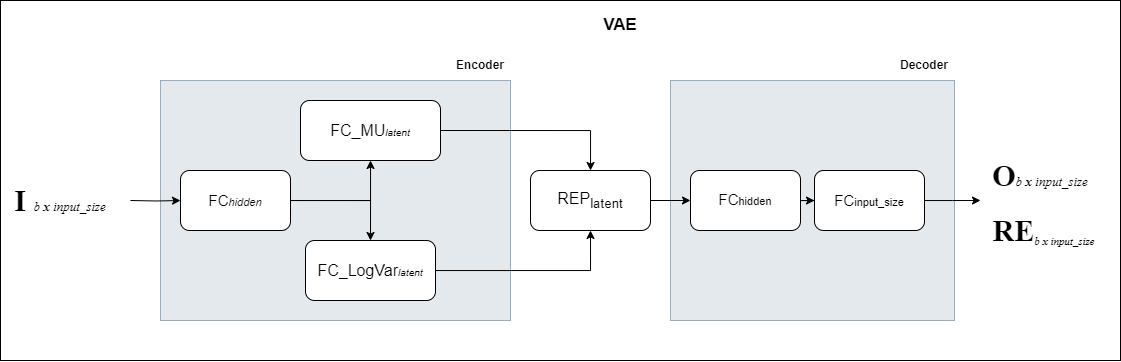

In [34]:
 # Define VAE model
ae = AE(input_size, hidden_size, latent_size, device = device).to(device)
_,_ = ae.fit(trdata_loader, num_epochs=epochs, plot_history = False)

Epoch 1/10, Loss: 0.0775


Epoch 2/10, Loss: 0.0595


Epoch 3/10, Loss: 0.0479


Epoch 4/10, Loss: 0.0414


Epoch 5/10, Loss: 0.0364


Epoch 6/10, Loss: 0.0284


Epoch 7/10, Loss: 0.0259


Epoch 8/10, Loss: 0.0218


Epoch 9/10, Loss: 0.0207


Epoch 10/10, Loss: 0.0227


In [35]:
ae_preds_test,ae_signal_test = ae.predict(tsdata_loader)

In [36]:
# Convert into dataframe
ae_preds_test = pd.DataFrame(ae_preds_test.cpu().detach().numpy(), columns = target_cols)
ae_signal_test_col = pd.Series(ae_signal_test.mean(dim = 0).cpu().detach().numpy(), index = target_cols)
ae_signal_test_row = pd.Series(ae_signal_test.mean(dim = 1).cpu().detach().numpy())
ae_signal_test = pd.DataFrame(ae_signal_test.cpu().detach().numpy(), columns = target_cols)

### Signal comparison (ground truth vs prediction)

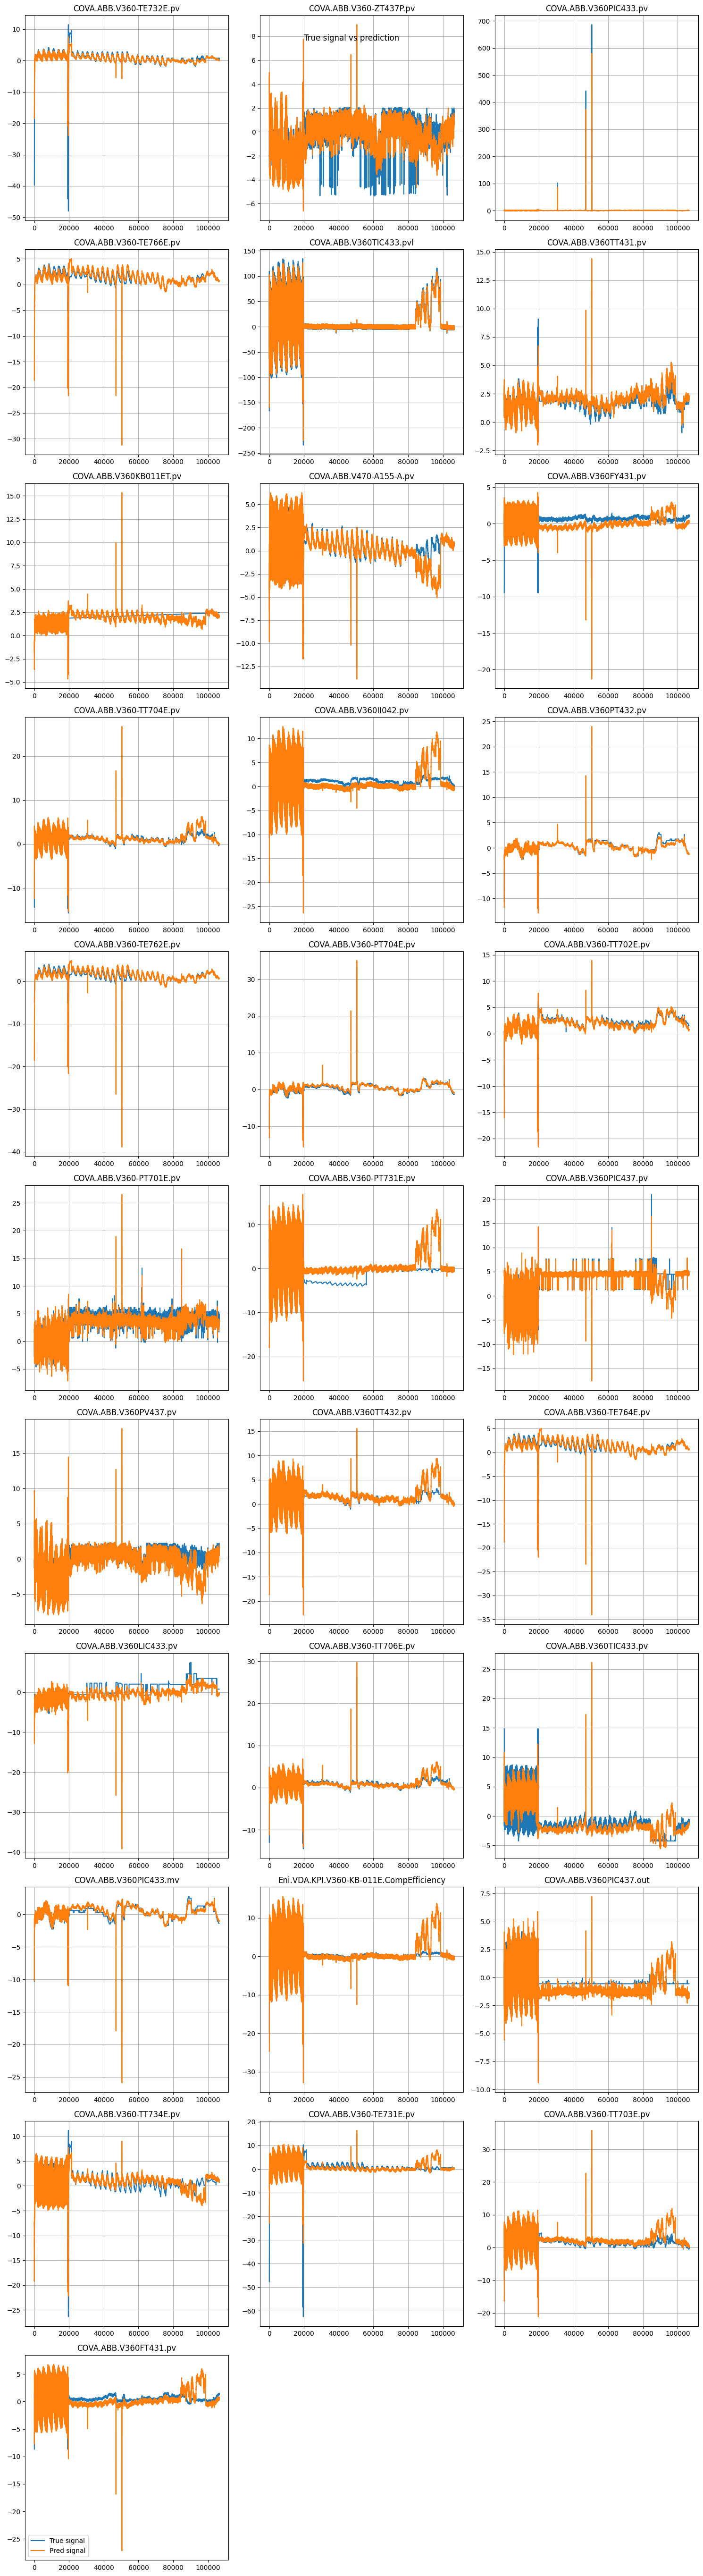

In [37]:
plot_predicted_on_real_signal(test_df[target_cols], ae_preds_test)

### Plot the signal reconstruction error by feature

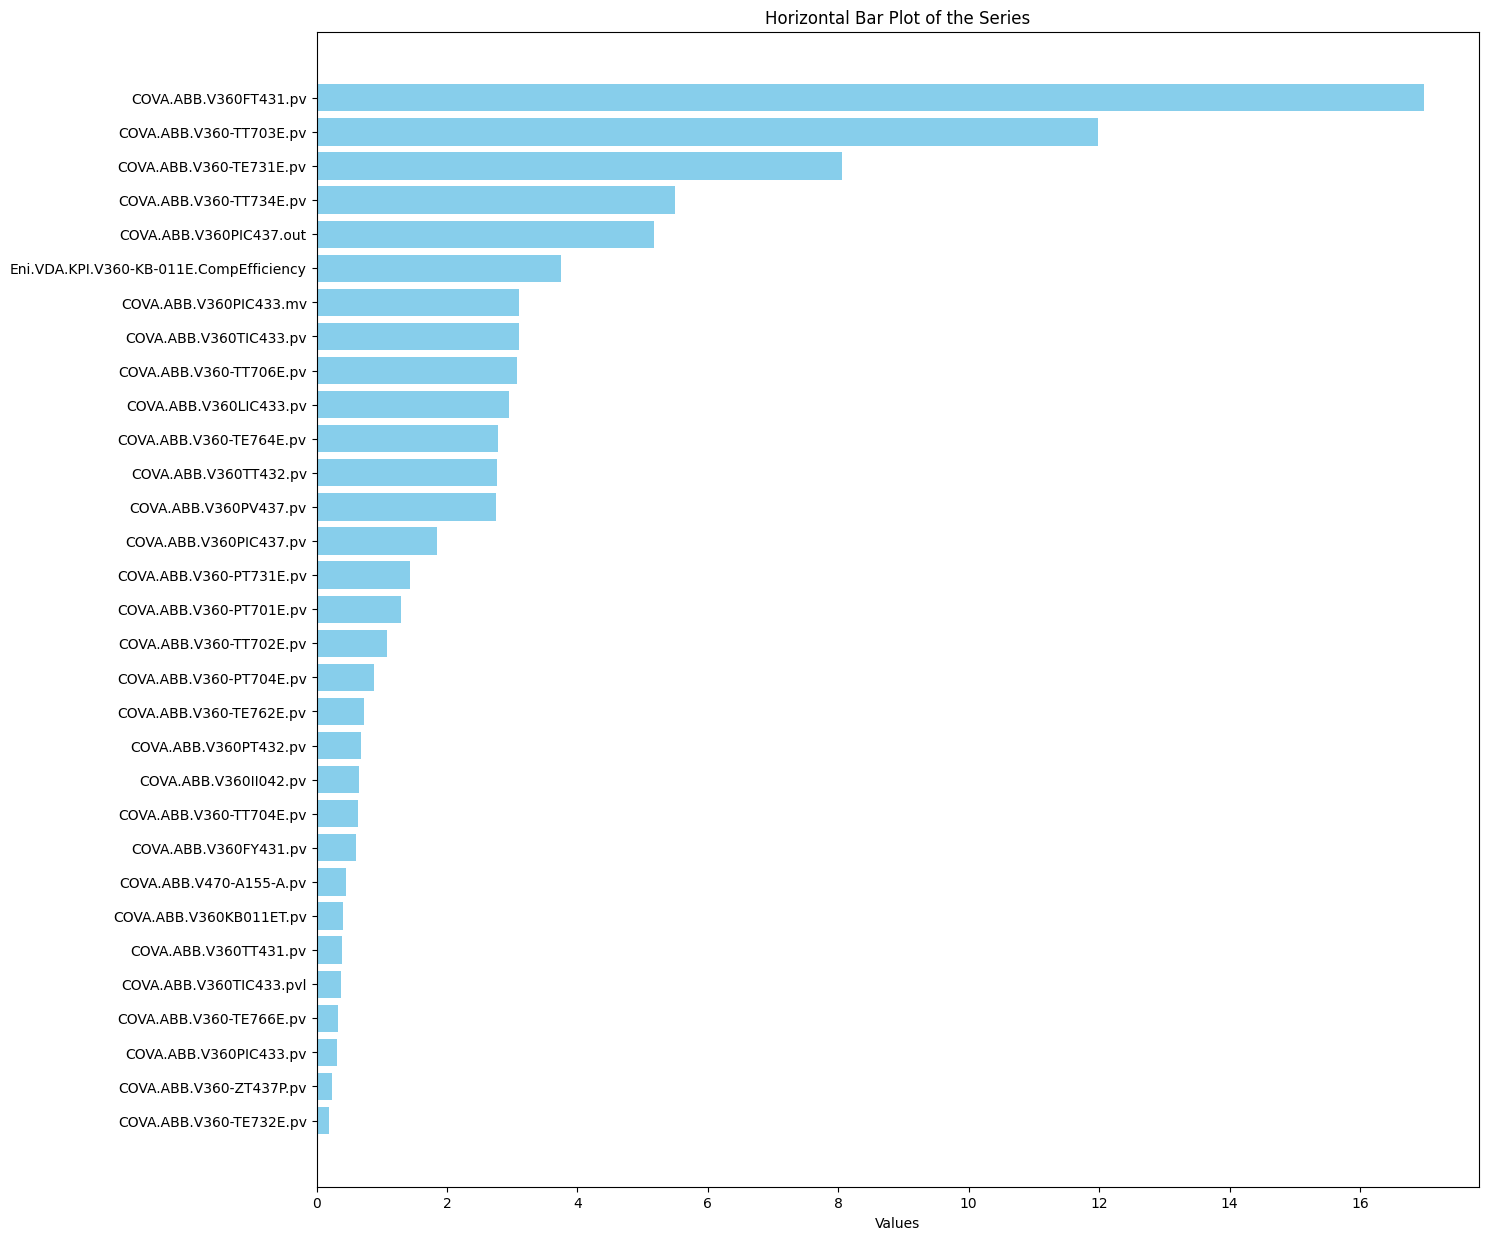

In [38]:
plt.figure(figsize=(15, 15))
plt.barh(target_cols, ae_signal_test_col.sort_values(ascending = True), color='skyblue')
plt.xlabel('Values')
plt.title('Horizontal Bar Plot of the Series')
plt.show()

### Find the best threshold
Threshold optimization using different methos

In [39]:
# Possible methods = ['bayesian' , 'simple' , 'cross_validation']
ae_best_threshold, ae_best_score = threshold_optimization(ae_signal_test_row, test_df['anomaly'], method = 'bayesian')

/usr/local/lib/python3.11/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [0.08721941709518433] before, using random point [211.3946841769113]
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/skopt/optimizer/optimizer.py:517: UserWarning: The objective has been evaluated at point [0.08721941709518433] before, using random point [417.4307125311317]
  warnings.warn(


### Plot the reconstruction error with anomaly threshold

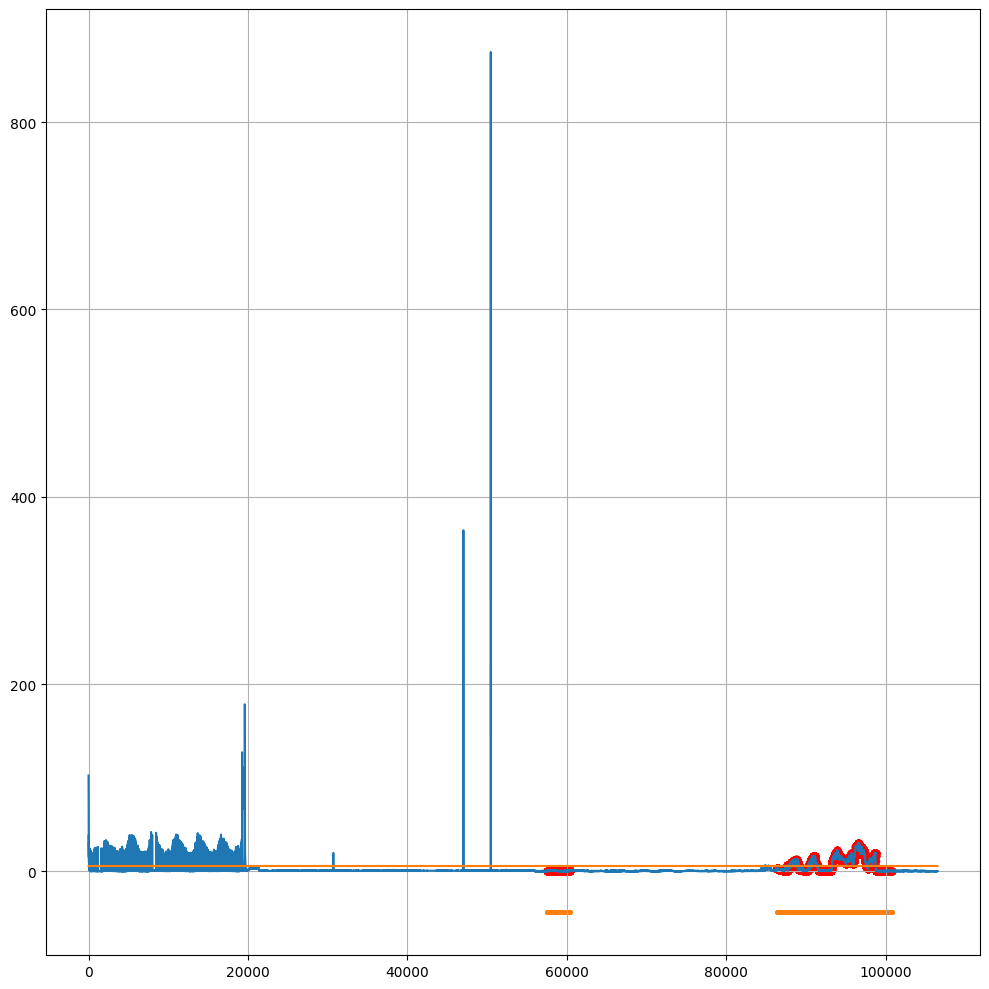

In [40]:
plot_signal(ae_signal_test_row, labels =true_labels ,threshold = ae_best_threshold)

## AE_LSTM

An LSTM-based Autoencoder (AE-LSTM) implementation:

- Encoder: Uses an LSTM layer to encode the input sequence into a hidden state, which is then passed through a fully connected layer to map it to the latent space.
- Decoder: Uses another LSTM to decode the latent vector by repeating it for each timestep in the sequence, then a dense layer reconstructs the original input sequence.
The loss function is the Mean Squared Error (MSE) between the input and reconstructed sequence.

Training: the Adam optimizer with early stopping. \
Output: A reconstructed version of the input and a reconstruction error signal with the same size of input.

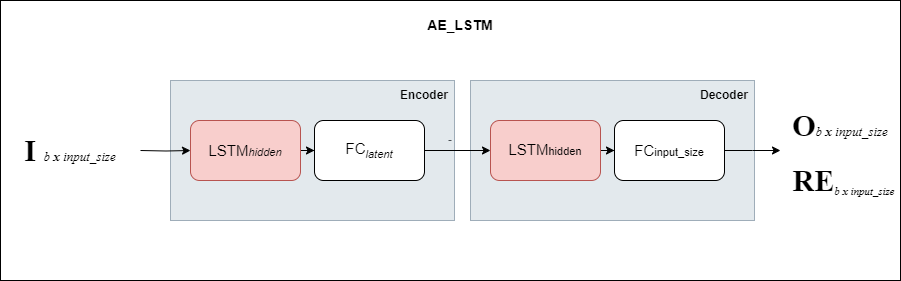

### Train

In [43]:
gc.collect()

3293

In [ ]:
# Define VAE model
ae_lstm = AE_LSTM(input_size, hidden_size, latent_size, device = device).to(device)
#best_epoch,_ = optimize_epochs(copy.deepcopy(ae), trdata_loader, valdata_loader, plot_history = True)
#print("best epoch : " , best_epoch)
_,_ = ae_lstm.fit(trdata_loader, num_epochs=epochs, plot_history = False)

Epoch 1/10, Loss: 0.1454


Epoch 2/10, Loss: 0.0913


Epoch 3/10, Loss: 0.0711


Epoch 4/10:  98%|█████████▊| 15820/16149 [03:19<00:03, 85.69it/s, loss=0.0133]

In [ ]:
ae_lstm_preds_test,ae_lstm_signal_test = ae_lstm.predict(tsdata_loader)

In [ ]:
ae_lstm_preds_test = pd.DataFrame(ae_lstm_preds_test.cpu().detach().numpy(), columns = target_cols)
ae_lstm_signal_test_col = pd.Series(ae_lstm_signal_test.mean(dim = 0).cpu().detach().numpy(), index = target_cols)
ae_lstm_signal_test_row = pd.Series(ae_lstm_signal_test.mean(dim = 1).cpu().detach().numpy())
ae_lstm_signal_test = pd.DataFrame(ae_lstm_signal_test.cpu().detach().numpy(), columns = target_cols)

### Signal comparison (ground truth vs prediction)


In [ ]:
plot_predicted_on_real_signal(test_df[target_cols], ae_lstm_preds_test)

### Plot the signal reconstruction error by feature

In [ ]:
plt.figure(figsize=(15, 15))
plt.barh(target_cols, ae_lstm_signal_test_col.sort_values(ascending = True), color='skyblue')
plt.xlabel('Values')
plt.title('Horizontal Bar Plot of the Series')
plt.show()

### Find the best threshold
Threshold optimization using different methos

In [ ]:
# Possible methods = ['bayesian' , 'simple' , 'cross_validation']
ae_lstm_best_threshold, ae_lstm_best_score = threshold_optimization(ae_lstm_signal_test_row, test_df['anomaly'], method = 'bayesian')

### Plot the reconstruction error with anomaly threshold

In [ ]:
plot_signal(ae_lstm_signal_test_row, labels =true_labels ,threshold = ae_lstm_best_threshold)

In [ ]:
print(np.mean(ae_signal_test))
print(np.mean(ae_lstm_signal_test))

## VAE

A Variational Autoencoder (VAE) implementation:

- **Encoder**: The encoder consists of fully connected layers that transform the input into two outputs—mean (mu) and log-variance (logvar)—which are used to generate latent space representations using the reparameterization trick.

- **Decoder**: The decoder reconstructs the original input from the latent space vector using two fully connected layers. The output is normalized using a sigmoid function to ensure values between 0 and 1.

- **Reparameterization**: In the latent space, the model samples from the distribution defined by mu and logvar using the formula: z = mu + std * eps, where eps is a random normal variable.

- **Loss Function**: Combines two components
*   Reconstruction Loss (MSE) between the original input and reconstructed output.
*   KL Divergence between the learned latent distribution and a standard Gaussian distribution to regularize the latent space.

- **Training**: The model is trained using the Adam optimizer with early stopping and tracks loss through epochs. The fit method handles training and optional validation, while also allowing the option to visualize training and validation loss over time.

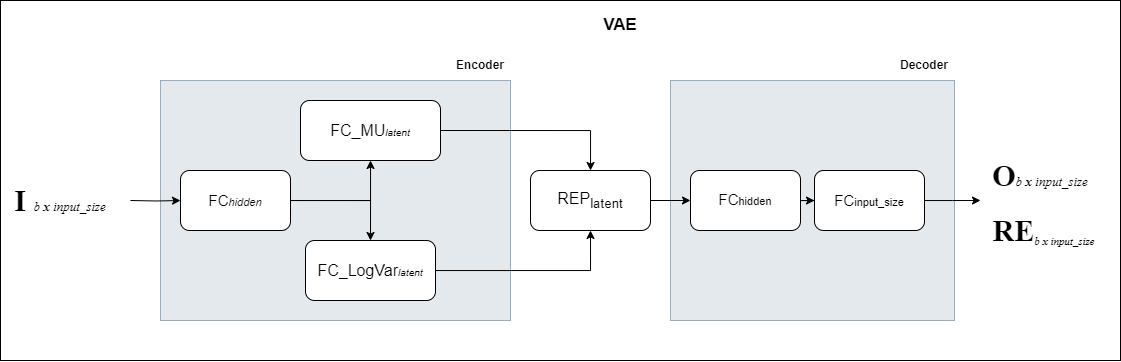

In [65]:
vae = VAE(input_size, hidden_size, latent_size, device = device).to(device)
_,_ = vae.fit(trdata_loader, num_epochs=epochs, plot_history = False)

Epoch 1/10, Loss: 14276929319.9310
Epoch 2/10, Loss: 68082.5030
Epoch 3/10, Loss: 3445164439294.6846
Epoch 4/10, Loss: 162119863544894856445367943168.0000
Epoch 5/10, Loss: 165194106365534092818137481216.0000
Early stopping!


In [66]:
vae_preds_test,vae_signal_test = vae.predict(tsdata_loader)

In [67]:
# Convert into dataframe
vae_preds_test = pd.DataFrame(vae_preds_test.cpu().detach().numpy(), columns = target_cols)
vae_signal_test_col = pd.Series(vae_signal_test.mean(dim = 0).cpu().detach().numpy(), index = target_cols)
vae_signal_test_row = pd.Series(vae_signal_test.mean(dim = 1).cpu().detach().numpy())
vae_signal_test = pd.DataFrame(vae_signal_test.cpu().detach().numpy(), columns = target_cols)

### Signal comparison (ground truth vs prediction)

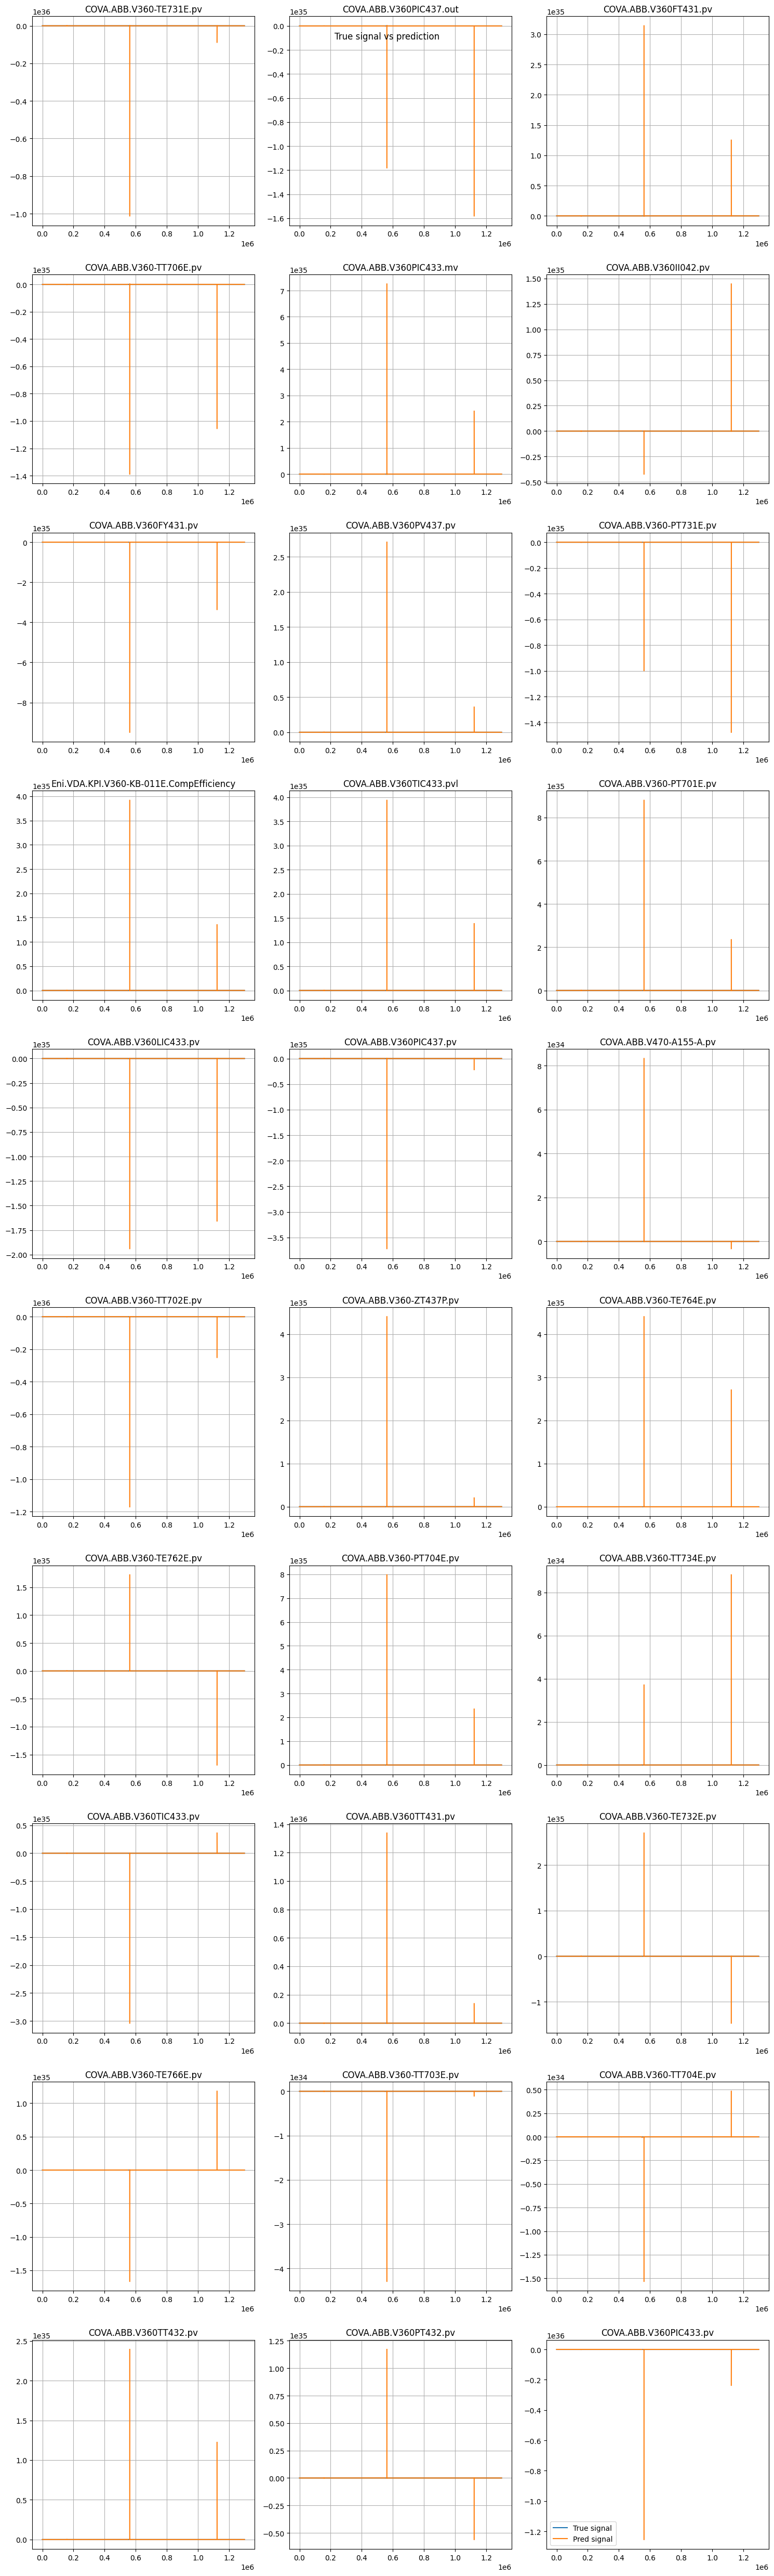

In [68]:
plot_predicted_on_real_signal(test_df[target_cols], vae_preds_test)

### Plot the signal reconstruction error by feature

In [42]:
vae_signal_test_col

NameError: name 'vae_signal_test_col' is not defined

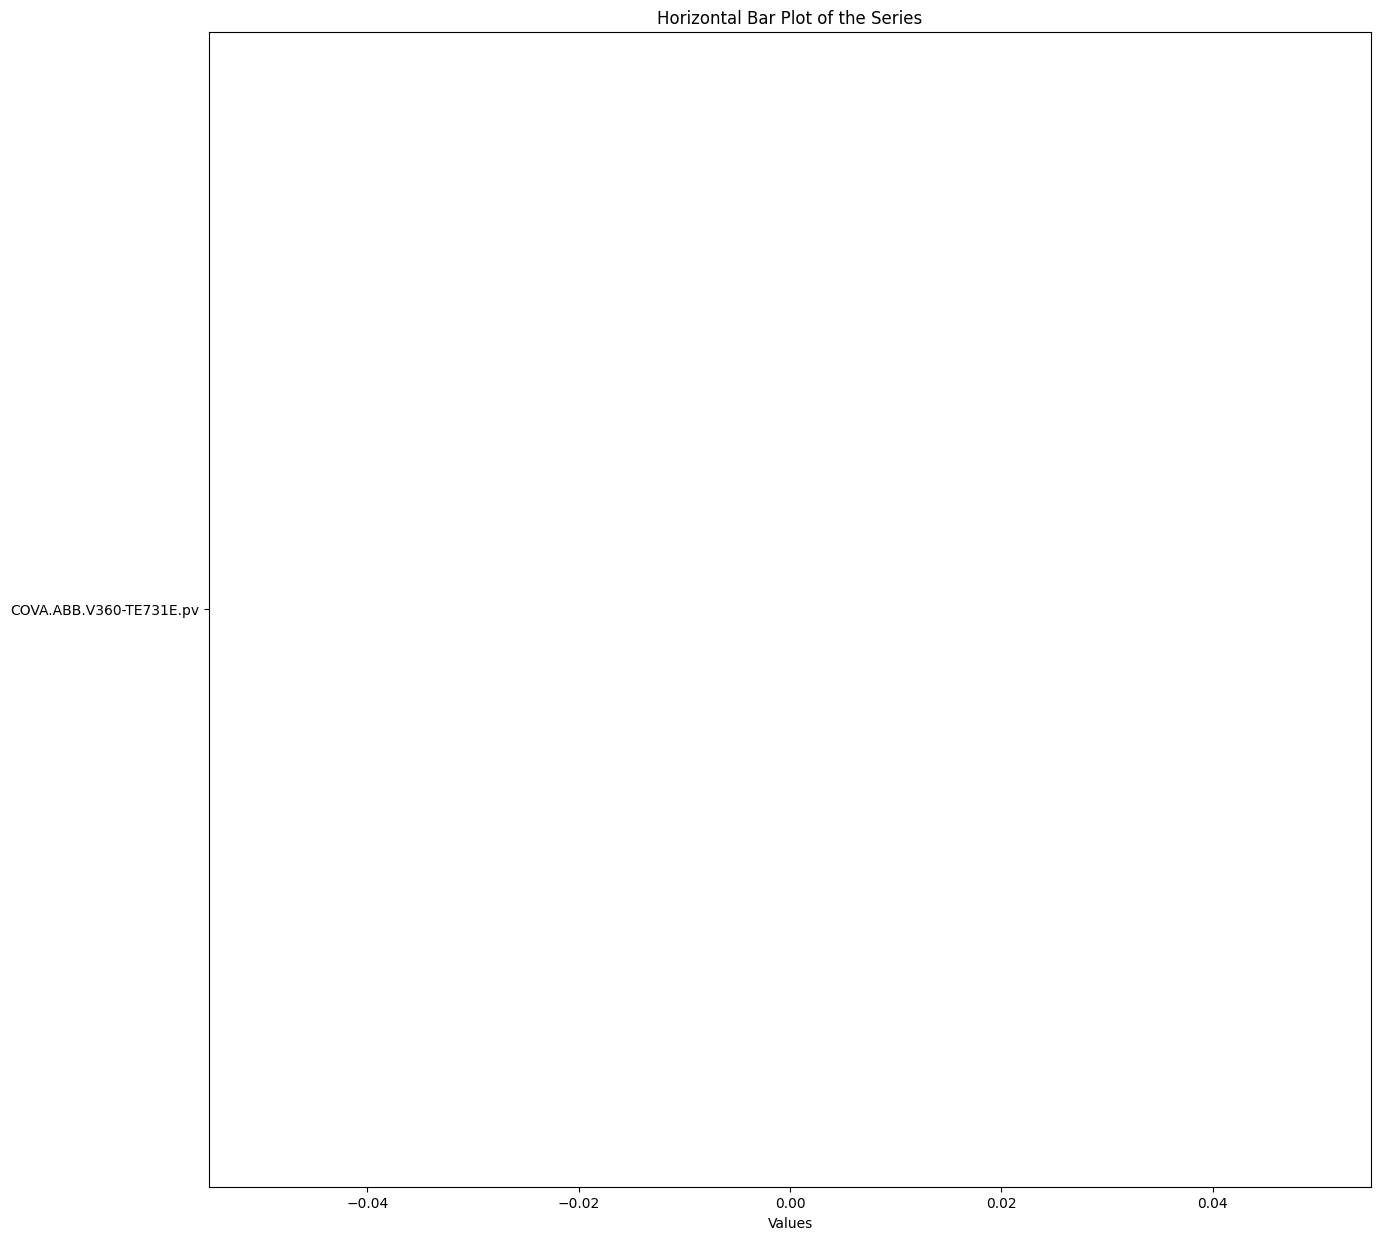

In [62]:
plt.figure(figsize=(15, 15))
plt.barh(target_cols, vae_signal_test_col.sort_values(ascending = True), color='skyblue')
plt.xlabel('Values')
plt.title('Horizontal Bar Plot of the Series')
plt.show()

### Find the best threshold
Threshold optimization using different methos

In [63]:
# Possible methods = ['bayesian' , 'simple' , 'cross_validation']
vae_best_threshold, vae_best_score = threshold_optimization(vae_signal_test_row, test_df['anomaly'], method = 'bayesian')

/usr/local/lib/python3.11/dist-packages/skopt/space/space.py:116: UserWarning: Dimension Real(low=nan, high=nan, prior='uniform', transform='identity') was inferred to Real(low=nan, high=nan, prior='uniform', transform='identity'). In upcoming versions of scikit-optimize, it will be inferred to Real(low=nan, high=nan, prior='uniform', transform='identity'). See the documentation of the check_dimension function for the upcoming API.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/skopt/space/space.py:116: UserWarning: Dimension Real(low=nan, high=nan, prior='uniform', transform='normalize') was inferred to Real(low=nan, high=nan, prior='uniform', transform='normalize'). In upcoming versions of scikit-optimize, it will be inferred to Real(low=nan, high=nan, prior='uniform', transform='normalize'). See the documentation of the check_dimension function for the upcoming API.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/skopt/space/space.py:116: UserWarning: Dimension Re

ValueError: Point ([nan]) is not within the bounds of the space ([(nan, nan)]).

### Plot the reconstruction error with anomaly threshold

In [ ]:
plot_signal(vae_signal_test_row, labels =true_labels ,threshold = vae_best_threshold)

## VAE_LSTM

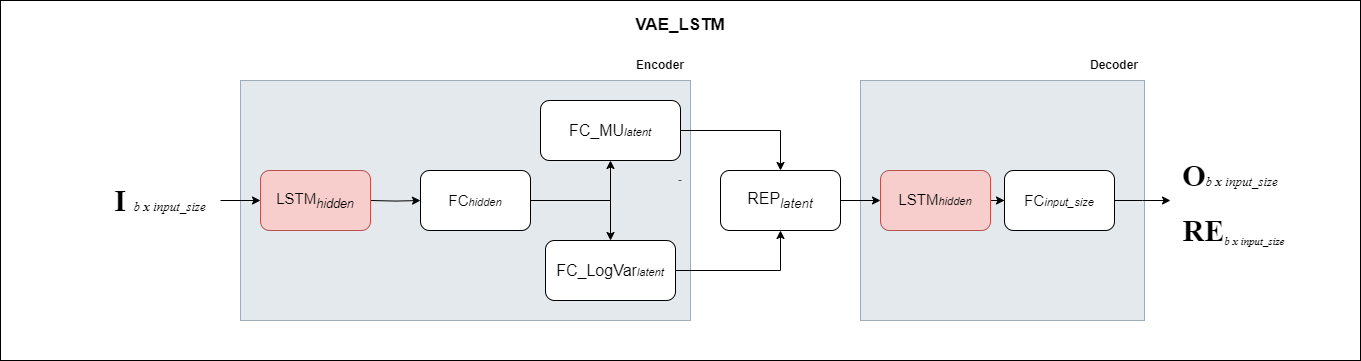

In [ ]:
vae_lstm = VAE_LSTM(input_size, hidden_size, latent_size, device = device).to(device)
_,_ = vae_lstm.fit(trdata_loader, num_epochs=epochs, plot_history = False)

In [ ]:
vae_lstm_preds_test,vae_lstm_signal_test = vae_lstm.predict(tsdata_loader)

In [ ]:
# Convert into dataframe
vae_lstm_preds_test = pd.DataFrame(vae_lstm_preds_test.cpu().detach().numpy(), columns = target_cols)
vae_lstm_signal_test_col = pd.Series(vae_lstm_signal_test.mean(dim = 0).cpu().detach().numpy(), index = target_cols)
vae_lstm_signal_test_row = pd.Series(vae_lstm_signal_test.mean(dim = 1).cpu().detach().numpy())
vae_lstm_signal_test = pd.DataFrame(vae_lstm_signal_test.cpu().detach().numpy(), columns = target_cols)

### Signal comparison (ground truth vs prediction)

In [ ]:
plot_predicted_on_real_signal(tsdata[target_cols], vae_lstm_preds_test)

### Plot the signal reconstruction error by feature

In [ ]:
plt.figure(figsize=(15, 15))
plt.barh(target_cols, vae_lstm_signal_test_col.sort_values(ascending = True), color='skyblue')
plt.xlabel('Values')
plt.title('Horizontal Bar Plot of the Series')
plt.show()

### Find the best threshold
Threshold optimization using different methos

In [ ]:
# Possible methods = ['bayesian' , 'simple' , 'cross_validation']
vae_lstm_best_threshold, vae_lstm_best_score = threshold_optimization(vae_lstm_signal_test_row, tsdata['anomaly'], method = 'bayesian')

### Plot the reconstruction error with anomaly threshold

In [ ]:
plot_signal(vae_lstm_signal_test_row, labels =true_labels ,threshold = vae_lstm_best_threshold)

# FInal Comparison

AE vs AE_LSTM

In [ ]:
print(f'The mean of MSE for AE is: {np.mean(ae_signal_test)}')
print(f'The mean of MSE for AE_LSTM is: {np.mean(ae_lstm_signal_test)}')

In [ ]:
labels = tsdata['anomaly']

plt.plot(ae_signal_test_row, label = "AE")
plt.plot(ae_lstm_signal_test_row, label = "AE-LSTM")

s = 4
nonzero = ae_signal_test_row.index[labels != 0]
smin, smax = np.min(ae_signal_test_row), np.max(ae_signal_test_row)
lvl = smin - 0.05 * (smax - smin)
if plt is not None:
      plt.scatter(nonzero, np.ones(len(nonzero)) * lvl, s=s, color='tab:red', label='labels')
else:
      plt.scatter(nonzero, np.ones(len(nonzero)) * lvl, s=s, color='tab:red', label='labels')
plt.legend()
plt.show()

VAE vs VAE_LSTM

In [ ]:
print(f'The mean of the reconstruction error + KL divergence for VAE is {np.mean(vae_signal_test)}')
print(f'The mean of the reconstruction error + KL divergence for VAE_LSTM is {np.mean(vae_lstm_signal_test)}')

In [ ]:
labels = tsdata['anomaly']

plt.plot(vae_signal_test_row, label = "AE")
plt.plot(vae_lstm_signal_test_row, label = "AE-LSTM")

s = 4
nonzero = vae_signal_test_row.index[labels != 0]
smin, smax = np.min(vae_signal_test_row), np.max(vae_signal_test_row)
lvl = smin - 0.05 * (smax - smin)
if plt is not None:
      plt.scatter(nonzero, np.ones(len(nonzero)) * lvl, s=s, color='tab:red', label='labels')
else:
      plt.scatter(nonzero, np.ones(len(nonzero)) * lvl, s=s, color='tab:red', label='labels')
plt.legend()
plt.show()

F1 in comparison

In [ ]:
score = pd.DataFrame(index = ['GMM', 'AE', 'AE_LSTM', 'VAE', 'VAE_LSTM'], columns = ['F1'])
score.loc['AE'] = ae_best_score
score.loc['AE_LSTM'] = ae_lstm_best_score
score.loc['VAE'] = vae_best_score
score.loc['VAE_LSTM'] = vae_lstm_best_score
score.loc['GMM'] = gmm_best_score

In [ ]:
score

In [ ]:
# Plotting
plt.figure(figsize=(10, 6))
bars = plt.bar(score.index, score['F1'], color='skyblue', edgecolor='black', linewidth=1.2)

# Adding data labels on top of each bar
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, yval + 0.01, round(yval, 3), ha='center', va='bottom')

# Customizing the plot
plt.title('F1 Scores by Models', fontsize=16, fontweight='bold')
plt.xlabel('Models', fontsize=14)
plt.ylabel('F1 Score', fontsize=14)
plt.ylim(0, 1.1)  # Assuming F1 scores are between 0 and 1
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

# Display plot
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

#Conclusion
All the 5 models performed very well on the test set. As we can see from the bar plot the baseline obtained the best results, but in our analysis this occurs because of a mislabeled anomaly in the test set. Indeed, we can see from the signal plots that in correspondece of the error-peaks of the 4 DL models there is a spike in the signal similar to anomalies.
The VAE_LSTM is the one that perform the best on this dataset, this could be related to the high degree of variability in data. The LSTM module handles better sequential dependencies and long-range temporal patterns.